# Visualize chest X-ray images and labels

Show four random samples from each split: train, test, and validation.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from data import ChestXrayDataset


In [2]:
datasets = {
    split: ChestXrayDataset(split=split)
    for split in ("train", "test", "val")
}
for split, dataset in datasets.items():
    print(f"{split}: {len(dataset):,} images")


train: 5,216 images
test: 624 images
val: 16 images


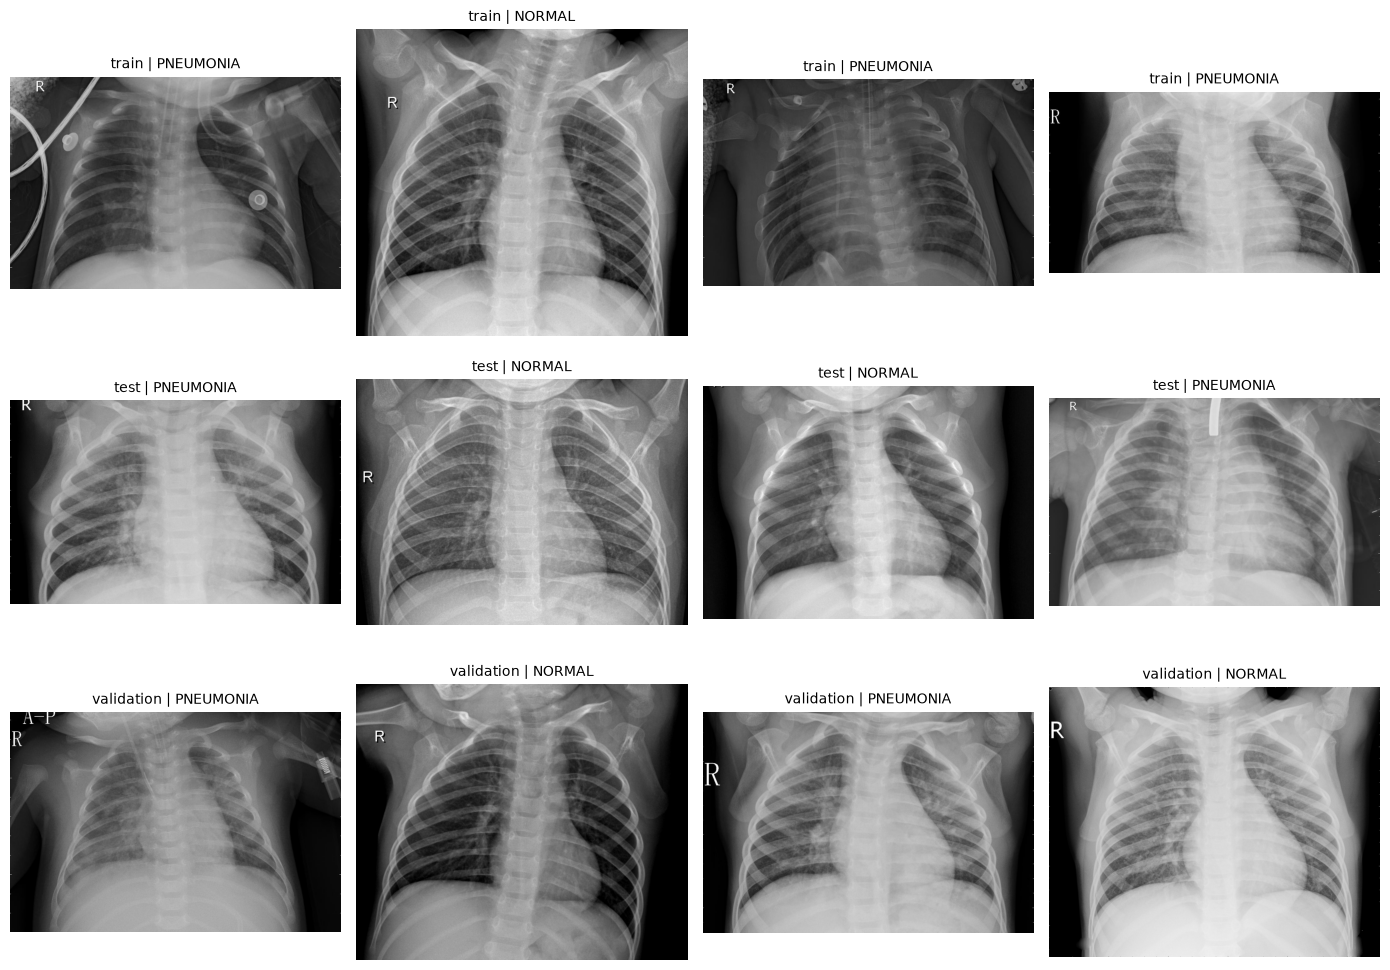

In [3]:
samples_per_split = 4
rng = np.random.default_rng(42)
fig, axes = plt.subplots(3, samples_per_split, figsize=(14, 10), squeeze=False)

for row, (split, dataset) in enumerate(datasets.items()):
    indices = rng.choice(len(dataset), size=samples_per_split, replace=False)
    split_name = "validation" if split == "val" else split
    for col, index in enumerate(indices):
        image, label = dataset[int(index)]
        ax = axes[row, col]
        ax.imshow(image.permute(1, 2, 0))
        ax.set_title(f"{split_name} | {dataset.classes[label]}", fontsize=10)
        ax.axis("off")

fig.tight_layout()
plt.show()
